# КТ 4 — трансформация запросов и реранкинг

Решения и выводы — в `reports/kt4.md`, здесь — эксперименты и цифры.

**Baseline — конфигурация КТ 3** (`gigarag.baseline`): BGE-M3 по чанку с префиксом метаданных + BM25
(k1 = 0,3, b = 1,0), взвешенная сумма alpha = 0,6, фильтр по патчу из запроса до отбора 100 кандидатов.
Dense — точный перебор numpy: Qdrant flat из КТ 3 — тоже точный перебор с теми же выдачами и добавляет
к запросу ~1,5 мс HTTP.

**Метрики** — как в КТ 3: P@k, R@k, NDCG@k (оценки 2/1), MAP, MRR. Решения — по validation (29 вопросов
с доказательствами), test (11) — только в итоговой таблице. Для негативных — `near@5`.

**Задержка** — по 100 запросам (50 вопросов gold в двух формулировках: после и до стилизации КТ 1), по одному
запросу, последовательно. Этапы: трансформация (LLM), эмбеддинг запроса, dense, BM25, слияние, реранкинг.
Время LLM — время ответа API при первом запросе, сохранённое в кэше (`ChatResponse.seconds`), остальное
меряется при каждом исполнении.

**Рассуждение LLM выключено** (`thinking: disabled`) во всех вызовах КТ 4. С ним `deepseek-flash` тратил
3–4 тыс. скрытых выходных токенов на listwise-ответ из десятка номеров: 90–95 % стоимости и времени этапа,
прогон КТ 4 обходился бы примерно в $3.5 и 2–3 часа LLM-вызовов. В КТ 2 (резюме и вопросы к чанкам) рассуждение
было включено — те цифры с этими несравнимы.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from gigarag import baseline, llm_rerank, metadata, metrics, query_expansion, tokens
from gigarag.cache import CacheStore, load_or_compute, read_npy, write_npy
from gigarag.corpus import Document, read_jsonl
from gigarag.embeddings import encode, load_sentence_model
from gigarag.enrich import PROVIDER, PROVIDER_BASE_URL, Usage
from gigarag.experiment import texts_fingerprint
from gigarag.gold import load_gold
from gigarag.llm import CachedChat, OpenAIChat
from gigarag.llm_rerank import ListwiseLlmReranker, PointwiseLlmReranker
from gigarag.pipeline import DENSE, HYBRID, HybridRetriever, Pipeline, bottleneck, run_all, stage_profile
from gigarag.relevance import build_qrels
from gigarag.rerank import CrossEncoderReranker, CrossEncoderSpec, load_cross_encoder
from gigarag.retrieval import Bm25Index
from gigarag.search import ranked_ids
from gigarag.stats import agreement_rate, pareto_front

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 220)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent  # ноутбук исполняется из notebooks/
DATA = ROOT / "data"
rows, CORPUS_SHA = read_jsonl(DATA / "corpus.jsonl")
items = load_gold(ROOT / "gold" / "gold.jsonl")
cache = CacheStore(DATA / "cache" / "kt4", CORPUS_SHA)
chat = CachedChat(OpenAIChat.from_env(ROOT / ".env", PROVIDER, PROVIDER_BASE_URL), DATA / "llm_cache")

tokenizer = tokens.load_tokenizer(baseline.EMBEDDER.name, baseline.EMBEDDER.revision)
corpus = baseline.build_corpus(tuple(Document(**r) for r in rows), tokenizer, cache)
passages = corpus.dense_texts  # чанк с префиксом метаданных: его читают и BGE-M3, и реранкеры
qrels = build_qrels(items, corpus.chunks, corpus.clean.aliases)

## 1. Baseline из КТ 3

In [2]:
embedder = load_sentence_model(baseline.EMBEDDER.name, baseline.EMBEDDER.revision,
                               max_seq_length=baseline.EMBEDDER.max_seq_length, half=True)
vectors = load_or_compute(
    cache.path("vectors", "npy", texts=texts_fingerprint(passages), half=True, **baseline.EMBEDDER.cache_params()),
    lambda: encode(embedder, passages), load=read_npy, save=write_npy)
retriever = HybridRetriever(vectors, Bm25Index.build(corpus.texts, baseline.BM25_K1, baseline.BM25_B),
                            baseline.ALPHA, baseline.POOL)


def encode_queries(texts) -> np.ndarray:
    return encode(embedder, list(texts), batch_size=len(texts))


# 100 запросов: gold-вопрос (ключ — qid) и его формулировка до стилизации (ключ — qid/original).
# Метрики считаются по первым, задержка — по всем ста.
gold_queries = {i.qid: i.question for i in items}
latency_queries = gold_queries | {f"{i.qid}/original": i.original_question or i.question for i in items}
patch_masks = metadata.filter_masks(metadata.patch_filter(corpus.meta, corpus.texts), corpus.meta, latency_queries)
encode_queries(["прогрев"])  # первая инициализация CUDA не в счёт
print(f"{len(corpus.chunks)} чанков; вопросов {len(items)}, запросов для замера {len(latency_queries)}, "
      f"с фильтром по патчу {len(patch_masks)}")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

19773 чанков; вопросов 50, запросов для замера 100, с фильтром по патчу 74


In [3]:
configs: dict[str, dict] = {}  # имя → трассы 100 запросов


def run(name: str, pipeline: Pipeline) -> dict:
    configs[name] = run_all(pipeline, latency_queries, patch_masks)
    return configs[name]


def evaluate(name: str) -> pd.DataFrame:
    ids = {qid: ranked_ids(configs[name][qid].ranking) for qid in gold_queries}
    return metrics.per_question(ids, qrels, items).assign(config=name, retriever="pipeline")


def near_negatives(name: str) -> pd.DataFrame:
    ids = {qid: ranked_ids(configs[name][qid].ranking) for qid in gold_queries}
    return metrics.negative_per_question(ids, qrels, items).assign(config=name)


COLUMNS = ["P@5", "R@5", "NDCG@5", "MAP", "MRR"]


def summary(names, split: str = "validation", columns=COLUMNS) -> pd.DataFrame:
    per_q = pd.concat([evaluate(n) for n in names])
    return (per_q[per_q["split"] == split].groupby("config", sort=False)[columns].mean() * 100).round(1)


def by_type(names) -> pd.DataFrame:
    """R@5 и NDCG@5 по типам вопросов (validation) и near@5 негативных."""
    per_q = pd.concat([evaluate(n) for n in names])
    table = per_q[per_q["split"] == "validation"].pivot_table(
        index="config", columns="qtype", values=["R@5", "NDCG@5"], sort=False).mul(100).round(1)
    negatives = pd.concat([near_negatives(n) for n in names])
    table[("near@5", "negative")] = negatives.query("split == 'validation'").groupby(
        "config", sort=False)["near@5"].mean().mul(100).round(1)
    return table


def latency(name: str) -> pd.Series:
    traces = list(configs[name].values())
    profile = stage_profile(traces)
    usage = Usage(len(traces), sum(t.prompt_tokens for t in traces), sum(t.completion_tokens for t in traces), 0)
    return pd.Series({"медиана, мс": profile.loc["итого", "медиана, мс"], "p95, мс": profile.loc["итого", "p95, мс"],
                      "токенов на запрос": (usage.prompt_tokens + usage.completion_tokens) / len(traces),
                      "$ на 1000 запросов": usage.cost_usd / len(traces) * 1000,
                      "bottleneck": bottleneck(profile)}, name=name)


BASELINE = "baseline (КТ 3)"
DENSE_ONLY = "dense (КТ 3, без BM25)"
run(BASELINE, Pipeline(retriever, encode_queries))
run(DENSE_ONLY, Pipeline(retriever, encode_queries, mode=DENSE))
display(summary([BASELINE, DENSE_ONLY]))
display(stage_profile(list(configs[BASELINE].values())).round(2))

,P@5,R@5,NDCG@5,MAP,MRR
config,,,,,
baseline (КТ 3),31.0,66.0,60.2,61.0,79.8
"dense (КТ 3, без BM25)",31.0,63.9,58.8,61.3,80.3


,"медиана, мс","p95, мс"
embed,6.22,7.80
dense,1.55,5.37
bm25,38.89,83.75
fusion,0.12,0.18
итого,47.57,97.22


## 2. Трансформация запроса: multi-query + RRF

**Почему multi-query, а не HyDE или step-back:**

- **Вопросы gold не похожи на текст корпуса.** Они длинные, разговорные, со сленгом и опечатками
  («Чё там с импетусом у энчи сделали в 7.29?», «насколько это отличается от прошлого значения»),
  а патчноуты называют героев и способности официальными английскими именами («Enchantress: Impetus …»).
  Переформулировка «на языке патчноута» помогает обоим поисковикам hybrid — и BM25 (точные имена),
  и dense.
- **30% вопросов — составные**: два патча, способность и её последствия. Отдельный запрос на каждую часть
  находит вторую половину ответа, которая словами исходного вопроса не начинается (в КТ 3 это слабое место
  dense).
- **HyDE опасен на этом корпусе.** Гипотетический ответ про баланс Dota выдумывает числа и номера патчей,
  а соседние патчи меняют ту же способность на другие числа: выдуманный «урон уменьшен с 60 до 55» ближе
  к правке не того патча. Кроме того, HyDE работает только для dense, а baseline — hybrid.
- **Step-back** помогает абстрактным вопросам (их 20%), но фактическим и составным только добавляет шум
  общего запроса. В multi-query «общий» запрос — третий вариант для вопросов с одной частью.

**Как устроено:** LLM (`deepseek-flash`, t = 0, seed 42, JSON) даёт 3 переформулировки, исходный вопрос ищется
тоже. Каждый из 4 запросов проходит весь baseline (hybrid + фильтр по патчу исходного вопроса), четыре выдачи
по 100 кандидатов сливаются RRF (k = 60): шкалы score у запросов разные, а места сравнимы. Фильтр берётся
из исходного вопроса: LLM может опустить номер патча или выдумать его.

In [4]:
expand = query_expansion.multi_query_expander(chat)
MULTI_QUERY = "+ multi-query"
run(MULTI_QUERY, Pipeline(retriever, encode_queries, expand=expand))
display(summary([BASELINE, MULTI_QUERY]).join(
    summary([BASELINE, MULTI_QUERY], "test", ["R@5", "NDCG@5"]).add_prefix("test ")))
display(by_type([BASELINE, MULTI_QUERY]))
per_q = pd.concat([evaluate(BASELINE), evaluate(MULTI_QUERY)])
display(pd.concat({metric: metrics.paired_changes(per_q, BASELINE, MULTI_QUERY, metric)
                   for metric in ("R@5", "NDCG@5")}, axis=1))
pd.DataFrame([latency(BASELINE), latency(MULTI_QUERY)])

,P@5,R@5,NDCG@5,MAP,MRR,test R@5,test NDCG@5
config,,,,,,,
baseline (КТ 3),31.0,66.0,60.2,61.0,79.8,53.8,57.3
+ multi-query,31.7,68.0,61.3,64.4,83.8,62.1,61.7


R@5                     NDCG@5                      near@5
qtype           factual composite abstract factual composite abstract negative
config                                                                        
baseline (КТ 3)    89.4      76.4     12.9    63.9      72.9     34.2      5.7
+ multi-query      93.9      78.2     11.4    69.6      73.9     28.4      2.9

R@5                    NDCG@5                   
          лучше хуже без изменений  лучше хуже без изменений
retriever                                                   
pipeline      2    1            26      8   13             8

,"медиана, мс","p95, мс",токенов на запрос,$ на 1000 запросов,bottleneck
baseline (КТ 3),47.565474,97.224943,0.00,0.000000,bm25
+ multi-query,1429.871526,1652.218561,486.35,0.224142,transform


Примеры переформулировок — по одному вопросу каждого типа:

In [5]:
examples = [next(i for i in items if i.qtype == qtype and i.split == "validation")
            for qtype in ("factual", "composite", "abstract", "negative")]
for item in examples:
    print(f"[{item.qtype}] {item.question}")
    for query in configs[MULTI_QUERY][item.qid].queries[1:]:
        print("   →", query)
broken = sum(len(configs[MULTI_QUERY][key].queries) == 1 for key in latency_queries)
print(f"\nзапросов без переформулировок (битый JSON или пустой ответ): {broken} из {len(latency_queries)}")

[factual] Я играю на Nature's Prophet и хочу лучше понимать его эффективность на ранней стадии после патча 7.35c. Подскажите, как изменился базовый урон этого героя с выходом этого обновления? Это важно для оценки его силы на лейнинге и расчёта дэмэджа на старте игры.
   → Как изменился базовый урон Nature's Prophet в патче 7.35c?
   → Nature's Prophet базовый урон изменение патч 7.35c
   → Обсуждение игроками силы Nature's Prophet на лейнинге после патча 7.35c
[composite] скажи пж как менялс рецпет и цена хевенс халберд в патчах 741 и 741ф
   → Как менялись рецепт и цена Heaven's Halberd в патчах 7.41 и 7.41f?
   → Heaven's Halberd: изменение рецепта и цены в патчах 7.41 и 7.41f
   → Обсуждения игроков и статьи о балансе Heaven's Halberd в патчах 7.41 и 7.41f
[abstract] в каком напрвлении были изменея карты в дота 2 в патче 7.40 и как это повлияло на иговые объекты и взимодействие с ними
   → Изменения карты в патче 7.40 Dota 2 и их влияние на игровые объекты и взаимодействие с ними
 

## 3. Cross-encoder

**Выбор модели.** Корпус русский со вставками английских имён, запросы — разговорные русские.
В организации `cross-encoder/*` модели обучены на английском MS MARCO (`ms-marco-*`, `ettin-reranker-*`),
немецком и на NLI/STS. Для поиска «вопрос → отрывок» на русском там одна подходящая — **mMiniLMv2-L12**,
обученная на mMARCO (машинный перевод MS MARCO на 14 языков, включая русский). Для проверки выбора её
сравнение на том же пуле:

| Модель | Параметры | Зачем в сравнении |
|---|---|---|
| `cross-encoder/ms-marco-MiniLM-L12-v2` | 33M | контроль: та же архитектура, только английский MS MARCO |
| `cross-encoder/mmarco-mMiniLMv2-L12-H384-v1` | 118M | основной кандидат: многоязычный mMARCO |
| `BAAI/bge-reranker-v2-m3` | 568M | многоязычный реранкер на базе BGE-M3 — верхняя планка качества |

Сравнение — пул 50 поверх baseline. Вход реранкера — вопрос и чанк с префиксом метаданных (номер патча часто
есть только в префиксе), не больше 512 токенов на пару, fp16 на GPU.

In [6]:
CROSS_ENCODERS = [
    CrossEncoderSpec("cross-encoder/ms-marco-MiniLM-L12-v2", "7b0235231ca2674cb8ca8f022859a6eba2b1c968", 33),
    CrossEncoderSpec("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1", "1427fd652930e4ba29e8149678df786c240d8825", 118),
    CrossEncoderSpec("BAAI/bge-reranker-v2-m3", "953dc6f6f85a1b2dbfca4c34a2796e7dde08d41e", 568),
]
SELECTION_POOL = 50
POOLS = (20, 50, 100)
cross_encoders = {}
for spec in CROSS_ENCODERS:
    model = load_cross_encoder(spec, half=True)
    model.predict([("прогрев", "прогрев")], show_progress_bar=False)
    cross_encoders[spec.short_name] = model
    run(f"+ CE {spec.short_name}, пул {SELECTION_POOL}",
        Pipeline(retriever, encode_queries, rerank=CrossEncoderReranker(model, passages, SELECTION_POOL)))
selection = [BASELINE, *(f"+ CE {s.short_name}, пул {SELECTION_POOL}" for s in CROSS_ENCODERS)]
selection_table = summary(selection).join(pd.DataFrame([latency(n) for n in selection]))
display(selection_table)
by_type(selection)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

,P@5,R@5,NDCG@5,MAP,MRR,"медиана, мс","p95, мс",токенов на запрос,$ на 1000 запросов,bottleneck
config,,,,,,,,,,
baseline (КТ 3),31.0,66.0,60.2,61.0,79.8,47.565474,97.224943,0.0,0.0,bm25
"+ CE ms-marco-MiniLM-L12-v2, пул 50",16.6,38.2,32.6,32.4,49.3,94.150490,129.517020,0.0,0.0,bm25
"+ CE mmarco-mMiniLMv2-L12-H384-v1, пул 50",23.4,54.0,45.4,46.6,60.5,88.782173,124.336351,0.0,0.0,bm25
"+ CE bge-reranker-v2-m3, пул 50",31.7,65.7,60.7,65.2,80.2,268.880068,308.407128,0.0,0.0,rerank


R@5                     NDCG@5                      near@5
qtype                                     factual composite abstract factual composite abstract negative
config                                                                                                  
baseline (КТ 3)                              89.4      76.4     12.9    63.9      72.9     34.2      5.7
+ CE ms-marco-MiniLM-L12-v2, пул 50          54.5      45.0      1.9    34.7      44.4     10.8      2.9
+ CE mmarco-mMiniLMv2-L12-H384-v1, пул 50    87.9      52.4      3.3    63.3      46.2     16.1      5.7
+ CE bge-reranker-v2-m3, пул 50              97.0      69.8     10.0    73.1      66.3     32.6      2.9

In [7]:
best_ce = max((s.short_name for s in CROSS_ENCODERS),
              key=lambda name: tuple(selection_table.loc[f"+ CE {name}, пул {SELECTION_POOL}", ["R@5", "NDCG@5"]]))
cross_encoder = cross_encoders[best_ce]
for unused in set(cross_encoders) - {best_ce}:
    del cross_encoders[unused]
torch.cuda.empty_cache()
print("cross-encoder для остальных экспериментов (R@5, затем NDCG@5):", best_ce)

cross-encoder для остальных экспериментов (R@5, затем NDCG@5): bge-reranker-v2-m3


### Размер пула и поверх чего реранкить

Пул 20 / 50 / 100 кандидатов от первичного поиска — поверх hybrid (baseline) и поверх одного dense
(тот же фильтр по патчу). R@10 показывает, сколько ответов вообще есть в пуле, R@5 и NDCG@5 — насколько
реранкер поднимает их наверх; время — только этап реранкинга.

In [8]:
pool_rows = []
for mode in (DENSE, HYBRID):
    for pool in POOLS:
        name = f"+ CE поверх {mode}, пул {pool}"
        run(name, Pipeline(retriever, encode_queries, mode=mode,
                           rerank=CrossEncoderReranker(cross_encoder, passages, pool)))
        stages = stage_profile(list(configs[name].values()))
        pool_rows.append({"config": name, "поверх": mode, "пул": pool,
                          "реранкинг, мс (медиана)": stages.loc["rerank", "медиана, мс"],
                          "реранкинг, мс (p95)": stages.loc["rerank", "p95, мс"]})
pool_table = pd.DataFrame(pool_rows).set_index("config").join(
    summary([r["config"] for r in pool_rows], columns=["R@1", "R@5", "R@10", "NDCG@5", "MRR"]))
display(summary([DENSE_ONLY, BASELINE], columns=["R@1", "R@5", "R@10", "NDCG@5", "MRR"]))
pool_table

,R@1,R@5,R@10,NDCG@5,MRR
config,,,,,
"dense (КТ 3, без BM25)",41.9,63.9,65.1,58.8,80.3
baseline (КТ 3),40.9,66.0,68.6,60.2,79.8


,поверх,пул,"реранкинг, мс (медиана)","реранкинг, мс (p95)",R@1,R@5,R@10,NDCG@5,MRR
config,,,,,,,,,
"+ CE поверх dense, пул 20",dense,20,89.945129,104.381569,40.1,60.5,65.3,58.0,78.4
"+ CE поверх dense, пул 50",dense,50,222.970968,237.259332,43.3,66.0,72.2,60.3,79.5
"+ CE поверх dense, пул 100",dense,100,439.880106,462.707743,43.0,66.4,72.2,59.0,77.6
"+ CE поверх hybrid, пул 20",hybrid,20,83.587253,97.087956,43.3,65.5,70.8,60.7,80.3
"+ CE поверх hybrid, пул 50",hybrid,50,212.186921,227.517341,43.3,65.7,72.1,60.7,80.2
"+ CE поверх hybrid, пул 100",hybrid,100,420.332796,436.649253,43.3,65.0,71.8,58.8,79.4


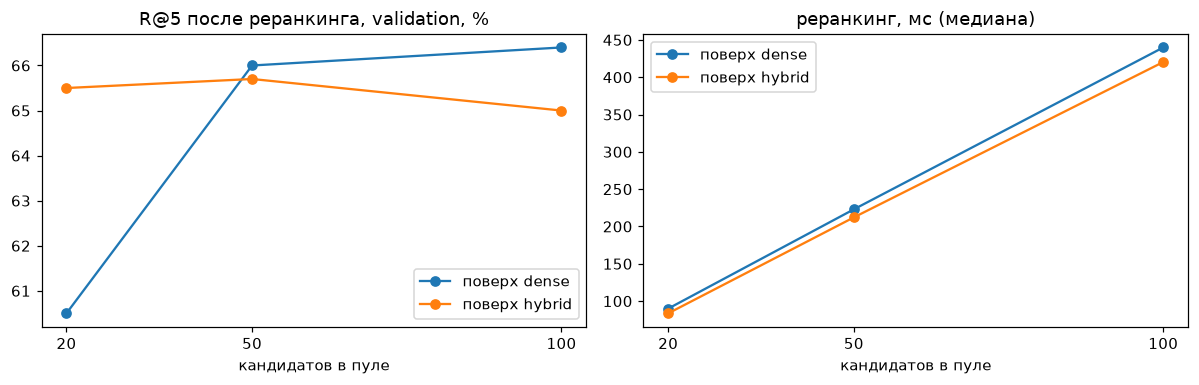

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for mode, group in pool_table.groupby("поверх", sort=False):
    axes[0].plot(group["пул"], group["R@5"], marker="o", label=f"поверх {mode}")
    axes[1].plot(group["пул"], group["реранкинг, мс (медиана)"], marker="o", label=f"поверх {mode}")
for ax, title in zip(axes, ["R@5 после реранкинга, validation, %", "реранкинг, мс (медиана)"], strict=True):
    ax.set_xlabel("кандидатов в пуле")
    ax.set_xticks(POOLS)
    ax.set_title(title)
    ax.legend()
plt.tight_layout()

In [10]:
hybrid_pools = pool_table[pool_table["поверх"] == HYBRID]
ce_pool = int(hybrid_pools.loc[max(hybrid_pools.index, key=lambda n: tuple(hybrid_pools.loc[n, ["R@5", "NDCG@5"]])),
                               "пул"])
CROSS_ENCODER = f"+ CE поверх {HYBRID}, пул {ce_pool}"
print("пул cross-encoder (лучший R@5, затем NDCG@5 поверх hybrid):", ce_pool)
by_type([BASELINE, CROSS_ENCODER])

пул cross-encoder (лучший R@5, затем NDCG@5 поверх hybrid): 50


R@5                     NDCG@5                      near@5
qtype                      factual composite abstract factual composite abstract negative
config                                                                                   
baseline (КТ 3)               89.4      76.4     12.9    63.9      72.9     34.2      5.7
+ CE поверх hybrid, пул 50    97.0      69.8     10.0    73.1      66.3     32.6      2.9

### Порог по score

В контекст идут чанки топ-5 со score ≥ порога. Precision — доля релевантных среди оставленных, recall — R@5
после отсечения. Порог выбирается по F1 на validation; отдельно — доля негативных вопросов, у которых
не осталось ни одного чанка (генератор получит пустой контекст и ответит «не знаю»).

лучший порог по F1 на validation: 0.4182


,precision,recall,F1,чанков в контексте,негативные без контекста
"порог, validation",,,,,
0.0002,31.7,65.7,42.8,5.0,0.0
0.4182,43.0,60.5,50.3,3.0,85.7


,precision,recall,F1,чанков в контексте,негативные без контекста
"порог, test",,,,,
0.0002,40.0,68.8,50.6,5.0,0.0
0.4182,46.2,60.6,52.4,3.5,66.7


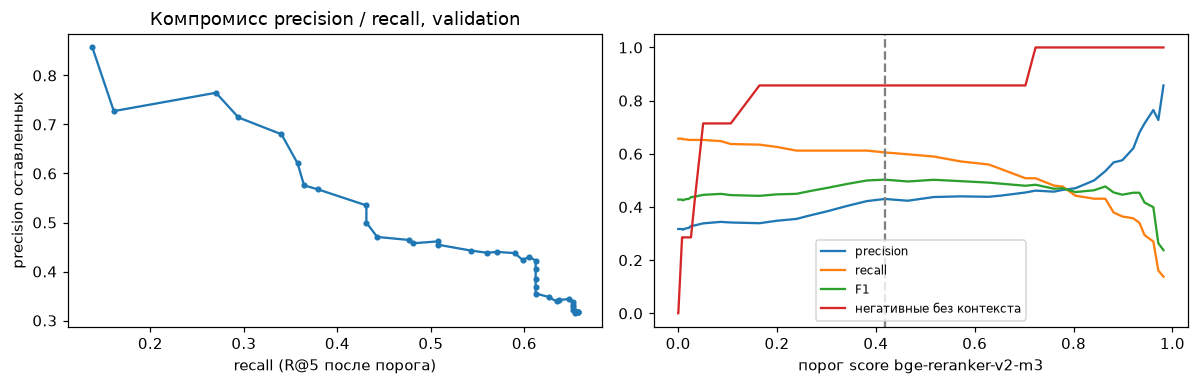

In [11]:
ce_rankings = {qid: configs[CROSS_ENCODER][qid].ranking for qid in gold_queries}
ce_scores = np.array([s for r in ce_rankings.values() for _, s in r[:metrics.CONTEXT_K]])
thresholds = np.unique(np.round(np.quantile(ce_scores, np.linspace(0, 0.95, 39)), 4))
validation_items = [i for i in items if i.split == "validation"]
curve = metrics.threshold_curve(ce_rankings, qrels, validation_items, thresholds)
best_threshold = float(curve.loc[curve["F1"].idxmax(), "порог"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(curve["recall"], curve["precision"], marker=".")
axes[0].set_xlabel("recall (R@5 после порога)")
axes[0].set_ylabel("precision оставленных")
axes[0].set_title("Компромисс precision / recall, validation")
for column in ("precision", "recall", "F1", "негативные без контекста"):
    axes[1].plot(curve["порог"], curve[column], label=column)
axes[1].axvline(best_threshold, color="grey", linestyle="--")
axes[1].set_xlabel(f"порог score {best_ce}")
axes[1].legend(fontsize=8)
plt.tight_layout()
test_curve = metrics.threshold_curve(ce_rankings, qrels, [i for i in items if i.split == "test"],
                                     [thresholds.min(), best_threshold])


def as_percent(table: pd.DataFrame) -> pd.DataFrame:
    """Доли — в проценты; среднее число чанков остаётся числом."""
    shares = ["precision", "recall", "F1", "негативные без контекста"]
    return table.set_index("порог").assign(**{c: table.set_index("порог")[c] * 100 for c in shares}).round(1)


print(f"лучший порог по F1 на validation: {best_threshold:.4f}")
display(as_percent(curve).loc[[thresholds.min(), best_threshold]].rename_axis("порог, validation"))
as_percent(test_curve).rename_axis("порог, test")

## 4. LLM как реранкер

`deepseek-flash` (t = 0, seed 42, JSON). Основной формат — **listwise**: вопрос и N пронумерованных чанков
одним запросом. Ошибки модели (повтор, выдуманный или пропущенный номер, лишняя оценка) чинятся: не названные
кандидаты остаются в исходном порядке. Для сравнения — **pointwise**: каждый чанк отдельным запросом с оценкой
0–2 (те же определения, что в разметке gold), N запросов идут параллельно, задержка этапа — самый медленный
из них.

### Промпт listwise: итерации и детерминизм

Детерминизм проверяется вторым прогоном тех же запросов с отдельным кэшем (`llm_cache/kt4_repeat`): модель
отвечает заново. 20 первых вопросов validation × пул 20 — самый длинный список, где порядок неустойчивее всего.
Совпадение — тот же порядок всего пула и тот же набор топ-5 (то, что уйдёт в контекст КТ 5). Порог задания — 90%.

- **v1 — отсортировать все.** Первая версия: полный порядок пула совпал лишь в 60% повторов. Модель
  переставляет почти равные кандидаты — десятый и пятнадцатый чанки «по теме» ей неразличимы.
- **v2 — оценки 0–2 всей пачке.** Тот же запрос, но вместо порядка — оценка каждому чанку по шкале pointwise;
  сортировка по оценке, при равенстве — исходный порядок первичного поиска. Ничьи разрешает код, а не модель.
- **v3 — выбрать до 5 лучших.** Модель называет только верх, остальные — в исходном порядке.

Правило выбора: среди версий с совпадением порядка ≥ 90% — лучшая по R@5, затем NDCG@5.

In [12]:
ITERATION_POOL = 20
repeat_chat = CachedChat(chat.client, DATA / "llm_cache" / "kt4_repeat")
probe = [i.qid for i in items if i.split == "validation"][:20]


def listwise_orders(client: CachedChat, prompt: llm_rerank.ListwisePrompt, pool: int) -> list[tuple[int, ...]]:
    """Порядок пула по каждому вопросу probe от одного прогона модели."""
    return [tuple(prompt.parse(client.complete(llm_rerank.listwise_request(
        gold_queries[qid], [passages[doc] for doc, _ in configs[BASELINE][qid].ranking[:pool]], prompt)).content,
        pool).order) for qid in probe]


def listwise_agreement(prompt: llm_rerank.ListwisePrompt, pool: int) -> pd.Series:
    first, second = (listwise_orders(c, prompt, pool) for c in (chat, repeat_chat))
    return pd.Series({"тот же порядок пула, %": agreement_rate(first, second),
                      "тот же топ-5, %": agreement_rate([frozenset(o[:5]) for o in first],
                                                       [frozenset(o[:5]) for o in second])}).mul(100)


def invalid_answers(prompt: llm_rerank.ListwisePrompt, pool: int) -> int:
    """Сколько из 100 ответов пришлось чинить (не по формату)."""
    return sum(not prompt.parse(chat.complete(llm_rerank.listwise_request(
        query, [passages[doc] for doc, _ in configs[BASELINE][key].ranking[:pool]], prompt)).content, pool).valid
        for key, query in latency_queries.items())


iteration_names = [f"+ LLM {p.name}, пул {ITERATION_POOL}" for p in llm_rerank.LISTWISE_PROMPTS]
iteration_rows = []
for prompt, name in zip(llm_rerank.LISTWISE_PROMPTS, iteration_names, strict=True):
    run(name, Pipeline(retriever, encode_queries, rerank=ListwiseLlmReranker(chat, passages, ITERATION_POOL, prompt)))
    iteration_rows.append(listwise_agreement(prompt, ITERATION_POOL).rename(name)
                          .to_frame().T.assign(**{"ответов с ошибкой": invalid_answers(prompt, ITERATION_POOL)}))
iterations = summary(iteration_names).join(pd.concat(iteration_rows)).join(
    pd.DataFrame([latency(n) for n in iteration_names]))
display(iterations.round(1))
stable = [(p, n) for p, n in zip(llm_rerank.LISTWISE_PROMPTS, iteration_names, strict=True)
          if iterations.loc[n, "тот же порядок пула, %"] >= 90]
listwise_prompt = max(stable, key=lambda pn: tuple(iterations.loc[pn[1], ["R@5", "NDCG@5"]]))[0]
print("промпт listwise для остальных экспериментов:", listwise_prompt.name)

,P@5,R@5,NDCG@5,MAP,MRR,"тот же порядок пула, %","тот же топ-5, %",ответов с ошибкой,"медиана, мс","p95, мс",токенов на запрос,$ на 1000 запросов,bottleneck
config,,,,,,,,,,,,,
"+ LLM v1: отсортировать все, пул 20",35.2,72.1,65.8,71.5,86.4,60.0,90.0,12,1246.6,1595.8,4447.7,1.4,rerank
"+ LLM v2: оценки 0–2 всей пачке, пул 20",35.2,71.8,67.4,71.7,88.2,100.0,100.0,10,1238.8,1835.4,4509.7,1.4,rerank
"+ LLM v3: выбрать до 5 лучших, пул 20",34.5,71.6,65.4,71.4,88.2,95.0,95.0,0,1051.0,1485.6,4418.7,1.3,rerank


промпт listwise для остальных экспериментов: v2: оценки 0–2 всей пачке


### Размер пула

Пул 5 / 10 / 20 поверх baseline с выбранным промптом и pointwise с пулом 10. При пуле 5 набор топ-5
не меняется — меняется только порядок (NDCG, MRR).

In [13]:
LLM_POOLS = (5, 10, 20)
for pool in LLM_POOLS:
    run(f"+ LLM listwise, пул {pool}",
        Pipeline(retriever, encode_queries, rerank=ListwiseLlmReranker(chat, passages, pool, listwise_prompt)))
POINTWISE_POOL = 10
run(f"+ LLM pointwise, пул {POINTWISE_POOL}",
    Pipeline(retriever, encode_queries, rerank=PointwiseLlmReranker(chat, passages, POINTWISE_POOL)))
llm_names = [BASELINE, *(f"+ LLM listwise, пул {p}" for p in LLM_POOLS), f"+ LLM pointwise, пул {POINTWISE_POOL}"]
llm_table = summary(llm_names).join(pd.DataFrame([latency(n) for n in llm_names]))
display(llm_table)
by_type(llm_names)

,P@5,R@5,NDCG@5,MAP,MRR,"медиана, мс","p95, мс",токенов на запрос,$ на 1000 запросов,bottleneck
config,,,,,,,,,,
baseline (КТ 3),31.0,66.0,60.2,61.0,79.8,47.565474,97.224943,0.00,0.000000,bm25
"+ LLM listwise, пул 5",31.0,66.0,62.4,66.4,83.9,1009.344244,1198.911540,1365.04,0.425226,rerank
"+ LLM listwise, пул 10",33.8,68.4,65.5,68.1,86.6,1114.249530,1376.739720,2410.72,0.751620,rerank
"+ LLM listwise, пул 20",35.2,71.8,67.4,71.7,88.2,1245.579122,1841.424903,4509.69,1.405611,rerank
"+ LLM pointwise, пул 10",33.1,68.2,63.9,67.3,86.6,1123.111168,1273.021729,4752.82,1.477254,rerank


R@5                     NDCG@5                      near@5
qtype                   factual composite abstract factual composite abstract negative
config                                                                                
baseline (КТ 3)            89.4      76.4     12.9    63.9      72.9     34.2      5.7
+ LLM listwise, пул 5      89.4      76.4     12.9    68.8      74.5     33.3      5.7
+ LLM listwise, пул 10     92.4      78.2     15.2    72.2      75.0     40.2      5.7
+ LLM listwise, пул 20     97.0      78.2     22.4    74.9      74.5     44.3      5.7
+ LLM pointwise, пул 10    92.4      78.2     14.3    71.0      74.8     35.6      5.7

In [14]:
print("ответов listwise с ошибкой (исправлены):", {pool: invalid_answers(listwise_prompt, pool) for pool in LLM_POOLS})
llm_pool = int(max(LLM_POOLS, key=lambda p: tuple(llm_table.loc[f"+ LLM listwise, пул {p}", ["R@5", "NDCG@5"]])))
LLM_RERANK = f"+ LLM listwise, пул {llm_pool}"
print("пул LLM-реранкера (лучший R@5, затем NDCG@5):", llm_pool)

ответов listwise с ошибкой (исправлены): {5: 6, 10: 6, 20: 10}
пул LLM-реранкера (лучший R@5, затем NDCG@5): 20


### Детерминизм выбранных конфигураций

- **pointwise**: 20 пар «вопрос — чанк» (первые 20 вопросов validation × первый кандидат baseline);
  совпадение — та же оценка;
- **listwise**: выбранный промпт и пул на тех же 20 вопросах.

In [15]:
pairs = [(gold_queries[qid], passages[configs[BASELINE][qid].ranking[0][0]]) for qid in probe]
grades = [[llm_rerank.parse_grade(c.complete(llm_rerank.pointwise_request(q, p)).content) for q, p in pairs]
          for c in (chat, repeat_chat)]
listwise_final = listwise_agreement(listwise_prompt, llm_pool)
determinism = pd.Series({
    "pointwise: та же оценка": 100 * agreement_rate(*grades),
    f"listwise ({listwise_prompt.name}, пул {llm_pool}): тот же порядок пула": listwise_final.iloc[0],
    f"listwise ({listwise_prompt.name}, пул {llm_pool}): тот же топ-5": listwise_final.iloc[1],
}).round(1)
determinism.to_frame("agreement, %")

,"agreement, %"
pointwise: та же оценка,100.0
"listwise (v2: оценки 0–2 всей пачке, пул 20): тот же порядок пула",100.0
"listwise (v2: оценки 0–2 всей пачке, пул 20): тот же топ-5",100.0


## 5. Комбинации: трансформация + реранкинг

Реранкер получает пул от multi-query (RRF четырёх запросов) и оценивает его по **исходному** вопросу:
переформулировки нужны, чтобы найти кандидатов, а судить о полезности надо по тому, что спросил пользователь.

In [16]:
MULTI_QUERY_CE = "+ multi-query + CE"
MULTI_QUERY_LLM = "+ multi-query + LLM-rerank"
run(MULTI_QUERY_CE, Pipeline(retriever, encode_queries, expand=expand,
                             rerank=CrossEncoderReranker(cross_encoder, passages, ce_pool)))
run(MULTI_QUERY_LLM, Pipeline(retriever, encode_queries, expand=expand,
                              rerank=ListwiseLlmReranker(chat, passages, llm_pool, listwise_prompt)))
ladder = {BASELINE: "baseline (КТ 3)", MULTI_QUERY: "+ трансформация (multi-query)",
          CROSS_ENCODER: f"+ cross-encoder ({best_ce}, пул {ce_pool})",
          LLM_RERANK: f"+ LLM-rerank (listwise {listwise_prompt.name[:2]}, пул {llm_pool})",
          MULTI_QUERY_CE: "+ трансформация + cross-encoder", MULTI_QUERY_LLM: "+ трансформация + LLM-rerank"}
by_type(list(ladder))

R@5                     NDCG@5                      near@5
qtype                      factual composite abstract factual composite abstract negative
config                                                                                   
baseline (КТ 3)               89.4      76.4     12.9    63.9      72.9     34.2      5.7
+ multi-query                 93.9      78.2     11.4    69.6      73.9     28.4      2.9
+ CE поверх hybrid, пул 50    97.0      69.8     10.0    73.1      66.3     32.6      2.9
+ LLM listwise, пул 20        97.0      78.2     22.4    74.9      74.5     44.3      5.7
+ multi-query + CE            97.0      70.6     11.0    74.0      65.6     35.8      2.9
+ multi-query + LLM-rerank    97.0      81.2     21.9    75.0      75.7     41.9      2.9

## 6. Профиль задержки по этапам

Медиана и p95 каждого этапа по 100 запросам, мс; bottleneck — этап с наибольшей медианой.

In [17]:
profiles = pd.concat({ladder[name]: stage_profile(list(configs[name].values())) for name in ladder}, axis=0)
display(profiles.round(1).unstack(level=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False))
pd.Series({ladder[name]: bottleneck(stage_profile(list(configs[name].values()))) for name in ladder},
          name="bottleneck").to_frame()

bm25               dense               embed              fusion              rerank           transform               итого        
                                             медиана, мс p95, мс медиана, мс p95, мс медиана, мс p95, мс медиана, мс p95, мс медиана, мс p95, мс медиана, мс p95, мс медиана, мс p95, мс
baseline (КТ 3)                                     38.9    83.8         1.6     5.4         6.2     7.8         0.1     0.2         NaN     NaN         NaN     NaN        47.6    97.2
+ трансформация (multi-query)                       99.3   146.8         3.2    14.1         6.4     6.8         0.4     0.5         NaN     NaN      1309.8  1530.4      1429.9  1652.2
+ cross-encoder (bge-reranker-v2-m3, пул 50)        43.2    83.1         1.9     4.0         5.2     5.9         0.1     0.2       212.2   227.5         NaN     NaN       269.5   300.8
+ LLM-rerank (listwise v2, пул 20)                  40.0    82.7         1.6     4.9         6.1     7.4         0.1     0.1      1203.8  1766.8         NaN     NaN      1245.6  1841.4
+ трансформация + cross-encoder                     94.9   149.5         3.7     8.1         6.0     6.5         0.4     0.5       208.1   209.6      1309.8  1530.4      1627.6  1863.9
+ трансформация + LLM-rerank                        98.8   148.0         3.1    13.5         6.4     6.8         0.4     0.5      1137.6  1602.1      1309.8  1530.4      2626.1  2961.2

,bottleneck
baseline (КТ 3),bm25
+ трансформация (multi-query),transform
"+ cross-encoder (bge-reranker-v2-m3, пул 50)",rerank
"+ LLM-rerank (listwise v2, пул 20)",rerank
+ трансформация + cross-encoder,transform
+ трансформация + LLM-rerank,transform


## 7. Задержка против Recall@5

Все конфигурации КТ 4, кроме итераций промпта listwise (раздел 4) и повтора «CE bge-reranker-v2-m3, пул 50»
(это та же конфигурация, что «CE поверх hybrid, пул 50»). Ось X — медиана end-to-end задержки (логарифмическая:
от миллисекунд до секунд LLM), Y — R@5 на validation. Подписаны ступени итоговой таблицы (крупные точки)
и парето-фронт (пунктир): конфигурации, которые никто не обходит одновременно по задержке и R@5.

,R@5,NDCG@5,"медиана, мс","p95, мс",токенов на запрос,$ на 1000 запросов,bottleneck,парето
config,,,,,,,,
"dense (КТ 3, без BM25)",63.9,58.8,6.2,10.7,0.0,0.0,embed,True
baseline (КТ 3),66.0,60.2,47.6,97.2,0.0,0.0,bm25,True
"+ CE mmarco-mMiniLMv2-L12-H384-v1, пул 50",54.0,45.4,88.8,124.3,0.0,0.0,bm25,False
"+ CE ms-marco-MiniLM-L12-v2, пул 50",38.2,32.6,94.2,129.5,0.0,0.0,bm25,False
"+ CE поверх dense, пул 20",60.5,58.0,96.4,112.3,0.0,0.0,rerank,False
"+ CE поверх hybrid, пул 20",65.5,60.7,135.8,176.3,0.0,0.0,rerank,False
"+ CE поверх dense, пул 50",66.0,60.3,230.6,244.0,0.0,0.0,rerank,False
"+ CE поверх hybrid, пул 50",65.7,60.7,269.5,300.8,0.0,0.0,rerank,False
"+ CE поверх dense, пул 100",66.4,59.0,447.5,469.8,0.0,0.0,rerank,True


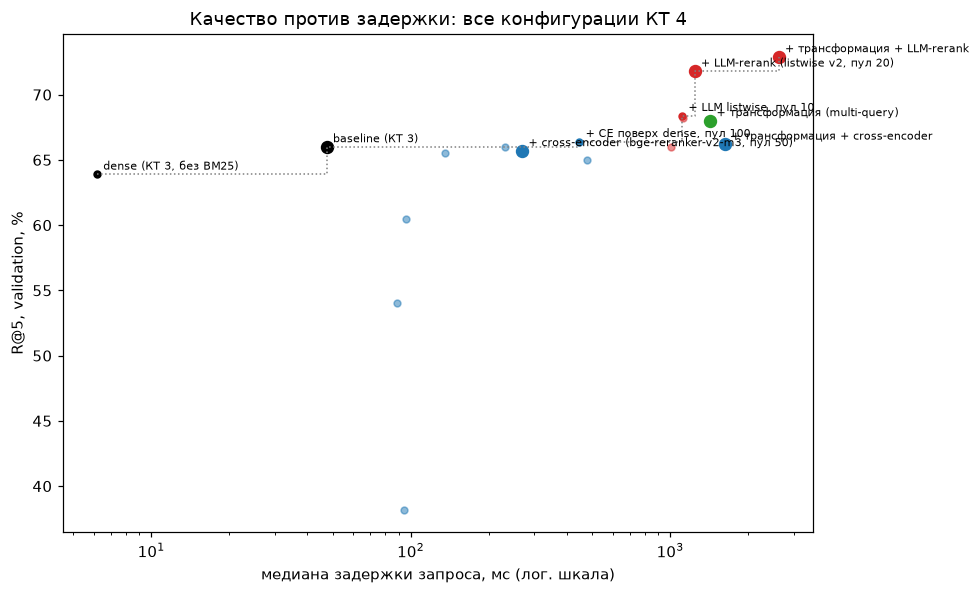

In [18]:
repeated = {f"+ CE {best_ce}, пул {SELECTION_POOL}"} if ce_pool == SELECTION_POOL else set()
all_names = [n for n in configs if n not in {*iteration_names, *repeated}]
tradeoff = summary(all_names, columns=["R@5", "NDCG@5"]).join(pd.DataFrame([latency(n) for n in all_names]))
tradeoff["парето"] = pareto_front(tradeoff["медиана, мс"].tolist(), tradeoff["R@5"].tolist())
fig, ax = plt.subplots(figsize=(9, 5.5))
families = {"CE": "tab:blue", "LLM": "tab:red", "multi-query": "tab:green"}
for name, row in tradeoff.iterrows():
    color = next((c for key, c in families.items() if key in name), "black")
    ax.scatter(row["медиана, мс"], row["R@5"], color=color, s=60 if name in ladder else 20,
               alpha=1 if name in ladder or row["парето"] else 0.5)
    if name in ladder or row["парето"]:
        ax.annotate(ladder.get(name, name), (row["медиана, мс"], row["R@5"]), fontsize=7, xytext=(4, 3),
                    textcoords="offset points")
front = tradeoff[tradeoff["парето"]].sort_values("медиана, мс")
ax.step(front["медиана, мс"], front["R@5"], where="post", color="grey", linestyle=":", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("медиана задержки запроса, мс (лог. шкала)")
ax.set_ylabel("R@5, validation, %")
ax.set_title("Качество против задержки: все конфигурации КТ 4")
plt.tight_layout()
tradeoff.sort_values("медиана, мс").round(1)

## 8. Итоговая таблица

Конфигурации в порядке усложнения. Метрики — validation, R@5 и NDCG@5 — ещё и на test. Задержка — медиана
и p95 end-to-end по 100 запросам; токены и стоимость — LLM-этапы на один запрос, по пиковому тарифу DeepSeek
(оценка сверху).

In [19]:
final_table = summary(list(ladder)).join(summary(list(ladder), "test", ["R@5", "NDCG@5"]).add_prefix("test ")).join(
    pd.DataFrame([latency(n) for n in ladder])).rename(index=ladder)
final_table.round(1)

,P@5,R@5,NDCG@5,MAP,MRR,test R@5,test NDCG@5,"медиана, мс","p95, мс",токенов на запрос,$ на 1000 запросов,bottleneck
config,,,,,,,,,,,,
baseline (КТ 3),31.0,66.0,60.2,61.0,79.8,53.8,57.3,47.6,97.2,0.0,0.0,bm25
+ трансформация (multi-query),31.7,68.0,61.3,64.4,83.8,62.1,61.7,1429.9,1652.2,486.4,0.2,transform
"+ cross-encoder (bge-reranker-v2-m3, пул 50)",31.7,65.7,60.7,65.2,80.2,68.8,66.1,269.5,300.8,0.0,0.0,rerank
"+ LLM-rerank (listwise v2, пул 20)",35.2,71.8,67.4,71.7,88.2,68.2,67.8,1245.6,1841.4,4509.7,1.4,rerank
+ трансформация + cross-encoder,32.4,66.2,61.6,65.6,80.1,74.1,69.2,1627.6,1863.9,486.4,0.2,transform
+ трансформация + LLM-rerank,35.9,72.9,67.3,72.9,88.1,74.1,72.6,2626.1,2961.2,4565.5,1.5,transform


## 9. Выводы и выбор конфигурации для КТ 5

Метрики — validation (29 вопросов с доказательствами, один вопрос — 3,4 п. п. R@5); test (11 вопросов,
один — 9 п. п.) — для контроля, решения по нему не принимаются.

**Multi-query + RRF.** R@5 66,0 → 68,0, NDCG@5 60,2 → 61,3: лучше у 2 вопросов, хуже у 1 — в пределах шума.
Помогает фактическим (R@5 89,4 → 93,9) и немного составным (76,4 → 78,2), абстрактным вредит (NDCG@5
34,2 → 28,4): переформулировки сужают размытый вопрос. Цена — +1,4 с (генерация 1,3 с), 486 токенов
и $0,22 на 1000 запросов. Сам по себе не окупается; оправдан, когда бюджет задержки ≥ 2,5 с и важнее всего
составные вопросы: в паре с LLM-реранкером составные R@5 78,2 → 81,2.

**Cross-encoder.** Английский `ms-marco-MiniLM` и многоязычный `mmarco-mMiniLMv2` портят выдачу (R@5 38,2
и 54,0 против 66,0); `bge-reranker-v2-m3` — на уровне baseline (65,7). Фактическим он помогает (89,4 → 97,0),
составным вредит (76,4 → 69,8): пары «вопрос — чанк» оцениваются по отдельности, и топ-5 собирается вокруг
одной части вопроса. Поверх dense реранкер растёт с пулом (60,5 / 66,0 / 66,4 при 20 / 50 / 100) и догоняет
hybrid, поверх hybrid прироста нет (65,5 / 65,7 / 65,0); время растёт линейно, ≈ 4,2 мс на кандидата.
Порог 0,418 поднимает precision 31,7 → 43,0 при recall 65,7 → 60,5 и оставляет пустой контекст у 86%
негативных — это сигнал «не знаю» для КТ 5, а не способ поднять R@5.

**LLM-реранкер.** Listwise растёт с пулом и к 20 не выходит на плато: R@5 66,0 / 68,4 / 71,8, NDCG@5
62,4 / 65,5 / 67,4 при пуле 5 / 10 / 20. Задержка растёт медленно (1,0 → 1,25 с: ответ короткий,
растёт только вход), стоимость — линейно ($0,43 → $1,41 на 1000). Pointwise с пулом 10 даёт тот же R@5 при
худшем NDCG@5 (63,9 против 65,5) и вдвое большей стоимости. Главный выигрыш — абстрактные вопросы:
R@5 12,9 → 22,4. Детерминизм: полная сортировка (v1) повторялась в 60% случаев; оценки 0–2 всей пачке (v2) —
100% и по порядку, и по топ-5, при том же качестве.

**Bottleneck:** в baseline — BM25 (39 из 48 мс), с cross-encoder — реранкинг (212 из 270 мс), с LLM —
вызов LLM (1,2 из 1,25 с), в комбинациях с multi-query — генерация переформулировок (1,3 с).

**Выбор для КТ 5 — baseline + LLM listwise v2, пул 20.** На графике это колено парето-фронта: +5,8 п. п. R@5
и +7,2 п. п. NDCG@5 за +1,2 с. Следующая точка фронта — multi-query + LLM — добавляет 1,1 п. п. R@5 (меньше
одного вопроса) и ничего по NDCG@5 за ещё 1,4 с. Из cross-encoder на фронт попадает только пул 100 поверх
dense — +0,4 п. п. R@5 к baseline за +0,4 с. На test multi-query + LLM выглядит лучше (R@5 74,1 против
68,2) — если в КТ 5 составные вопросы окажутся главной потерей, это первая конфигурация для проверки.